# Question 4: have rents grown faster than wages?

Rent is Zillow's observed rent index (ZORI), averaged over each quarter; wages are the QCEW average weekly wage for that
quarter (all industries, all ownerships). Source: `gold.mart_metro_month`. The cumulative comparison runs from 2015 Q1
to the latest published QCEW quarter, the same quarter of the year at both ends because QCEW wages are seasonal.

Caveats: ZORI is asking rent for new leases, which moves faster than what sitting tenants pay. The average weekly wage
is total pay divided by jobs, so it rises when the job mix shifts toward high-paid work (Seattle and Austin tech) even
if typical pay does not. Months after the latest QCEW quarter are left out, not carried forward (`wages_is_carried_forward`).
Both series are nominal; deflating both by the same CPI does not change which grew faster.

In [1]:
import common as c
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter

In [2]:
d = c.rent_wage_gap("2015Q1")
print(d.attrs["window"])
d

2015Q1 to 2026Q1


,rent_growth,wage_growth,inflation,gap
metro,,,,
Atlanta,0.809,0.529,0.394,0.280
Phoenix,0.855,0.592,0.394,0.263
Tampa,0.888,0.695,0.394,0.193
Charlotte,0.716,0.559,0.394,0.157
Orlando,0.744,0.614,0.394,0.130
Dallas-Fort Worth,0.544,0.537,0.394,0.006
Nashville,0.578,0.631,0.394,-0.053
Raleigh,0.549,0.613,0.394,-0.063
Denver,0.486,0.646,0.394,-0.160


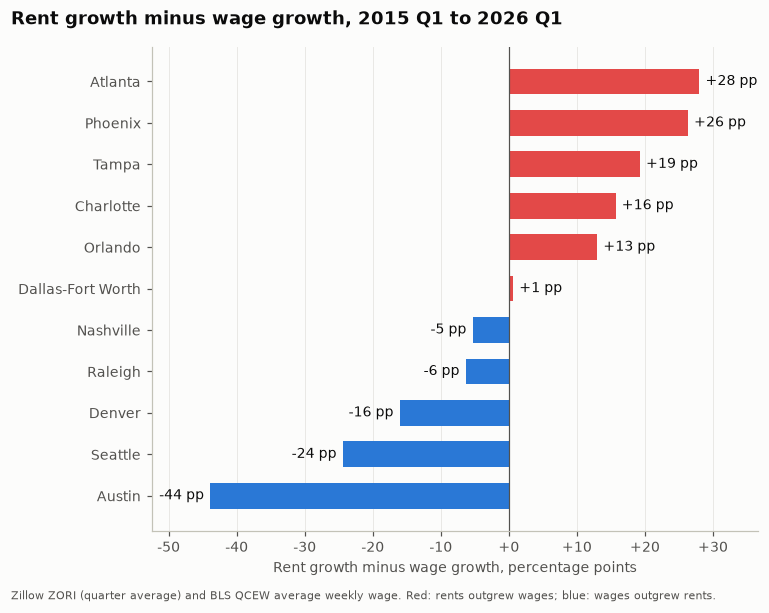

In [3]:
fig, ax = c.ranked_bars(
    d.gap * 100, "{:+.0f} pp", FuncFormatter(lambda v, _: f"{v:+.0f}"), diverging=True
)
ax.set_xlabel("Rent growth minus wage growth, percentage points")
c.save(
    fig,
    "q4_rent_minus_wage",
    f"Rent growth minus wage growth, {d.attrs['window'].replace('Q', ' Q')}",
    "Zillow ZORI (quarter average) and BLS QCEW average weekly wage. Red: rents outgrew wages; blue: wages outgrew rents.",
)

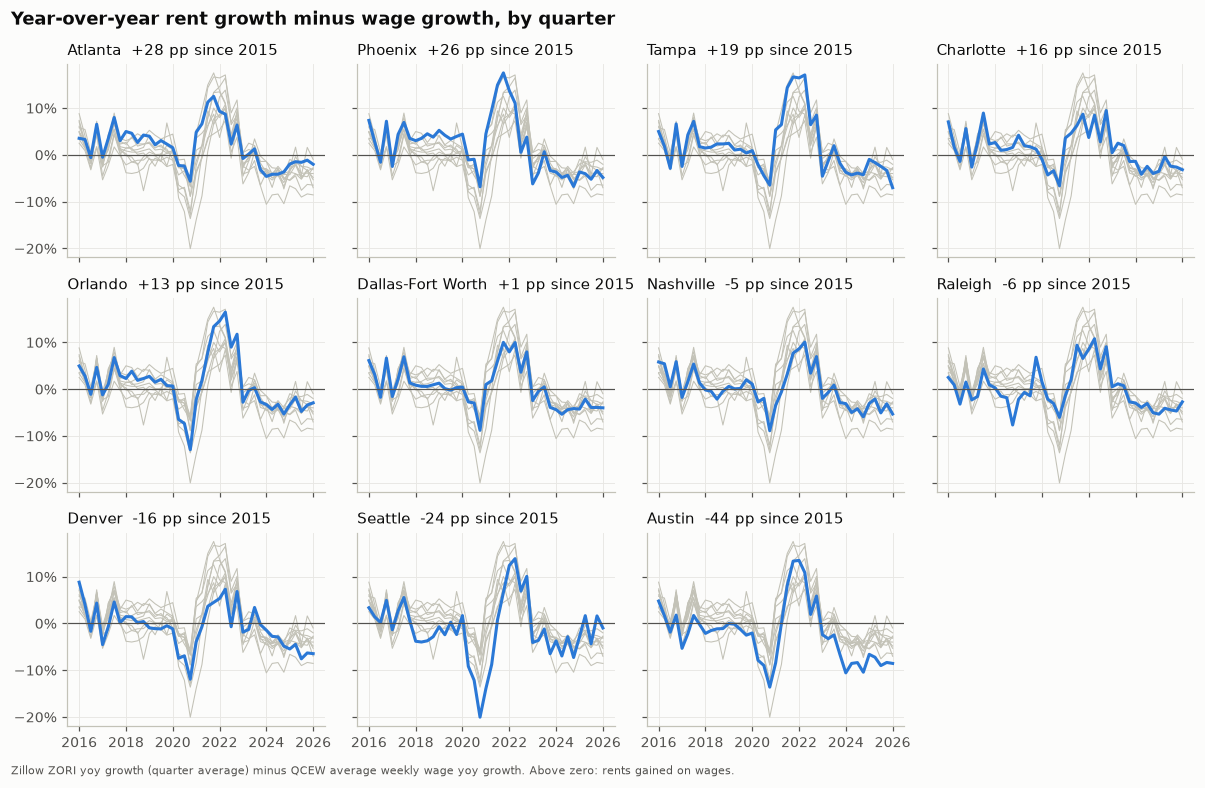

In [4]:
qd = c.quarterly().dropna(subset=["zori_yoy", "wage_yoy"])
qd["gap"] = qd.zori_yoy - qd.wage_yoy
wide = qd.pivot(index="quarter", columns="metro", values="gap")
wide.index = pd.PeriodIndex(wide.index, freq="Q").to_timestamp()
titles = {m: f"{m}  {g * 100:+.0f} pp since 2015" for m, g in d.gap.items()}
fig = c.small_multiples(
    wide, d.index, titles, PercentFormatter(1, decimals=0), zero=True
)
c.save(
    fig,
    "q4_gap_by_quarter",
    "Year-over-year rent growth minus wage growth, by quarter",
    "Zillow ZORI yoy growth (quarter average) minus QCEW average weekly wage yoy growth. Above zero: rents gained on wages.",
)

## Answer

In [5]:
hi, lo = d.iloc[0], d.iloc[-1]
print(
    f"From {d.attrs['window']}, rents outgrew wages in {(d.gap > 0).sum()} of {len(d)} metros: most in {d.index[0]} "
    f"(rents {hi.rent_growth:+.0%}, wages {hi.wage_growth:+.0%}, gap {hi.gap * 100:+.0f} pp); wages led most in "
    f"{d.index[-1]} (rents {lo.rent_growth:+.0%}, wages {lo.wage_growth:+.0%}, gap {lo.gap * 100:+.0f} pp)."
)

From 2015Q1 to 2026Q1, rents outgrew wages in 6 of 11 metros: most in Atlanta (rents +81%, wages +53%, gap +28 pp); wages led most in Austin (rents +34%, wages +78%, gap -44 pp).
